# Aviation Accidents Analysis

You are part of a consulting firm that is tasked to do an analysis of commercial and passenger jet airline safety. The client (an airline/airplane insurer) is interested in knowing what types of aircraft (makes/models) exhibit low rates of total destruction and low likelihood of fatal or serious passenger injuries in the event of an accident. They are also interested in any general variables/conditions that might be at play. Your analysis will be based off of aviation accident data accumulated from the years 1948-2023. 

Our client is only interested in airplane makes/models that are professional builds and could potentially still be active. Assume a max lifetime of 40 years for a make/model retirement and make sure to filter your data accordingly (i.e. from 1983 onwards). They would also like separate recommendations for small aircraft vs. larger passenger models. **In addition, make sure that claims that you make are statistically robust and that you have enough samples when making comparisons between groups.**


In this summative assessment you will demonstrate your ability to:
- Use Pandas to load, inspect, and clean the dataset appropriately. 
- Transform relevant columns to create measures that address the problem at hand.
- **conduct EDA: visualization and statistical measures to understand the structure of the data**
- **recommend a set of manufacturers to consider as well as specific airplanes conforming to the client's request**
- **discuss the relationship between serious injuries/airplane damage incurred and at least *two* factors at play in the incident. You must provide supporting evidence (visuals, summary statistics, tables) for each claim you make.**

In [2]:
# loading relevant packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Exploratory Data Analysis  
- Load in the cleaned data

In [3]:
df = pd.read_csv('cleaned_aviation_data.csv')
df.head(10)

/tmp/ipykernel_1145/514672248.py:1: DtypeWarning: Columns (0: Event.Id) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('cleaned_aviation_data.csv')


,Event.Id,Investigation.Type,Accident.Number,Event.Date,Location,Country,Latitude,Longitude,Airport.Code,Airport.Name,...,Total.Uninjured,Weather.Condition,Broad.phase.of.flight,Report.Status,Publication.Date,Total.Passengers,Likelihood.Fatal.Serious,is_destroyed,Make_Model,type_id
0,20001214X42478,Incident,LAX83IA149A,1983-03-18,"LOS ANGELES, CA",United States,NaN,NaN,LAX,LOS ANGELES INTL,...,588.0,vmc,taxi,Probable Cause,04-12-2014,590.0,0.003390,False,boeing 747,618
1,20001214X42331,Accident,ATL83FA140,1983-03-20,"CROSSVILLE, TN",United States,NaN,NaN,NaN,NaN,...,8.0,imc,cruise,Probable Cause,02-05-2011,10.0,0.200000,True,piper PA-28-140,1876
2,20001214X42672,Accident,FTW83LA177,1983-04-02,"MCKINNEY, TX",United States,NaN,NaN,TX05,AERO COUNTRY,...,4.0,vmc,standing,Probable Cause,17-10-2016,6.0,0.333333,False,de havilland DHC-6,1299
3,20001214X45013,Incident,CHI84IA041,1983-11-08,"CHICAGO, IL",United States,NaN,NaN,ORD,O'HARE,...,100.0,vmc,taxi,Probable Cause,11-06-2018,102.0,0.019608,False,boeing 727-200,537
4,20001214X45188,Accident,NYC84LA028,1983-11-13,"MARTHA'S VINEYARD, MA",United States,NaN,NaN,NaN,NaN,...,1.0,vmc,climb,Probable Cause,05-05-2011,3.0,0.666667,False,beech C35,406
5,20001214X45339,Accident,LAX84LA110,1983-12-22,"SANTA ROSA ISLAND, CA",United States,NaN,NaN,NaN,PRIVATE,...,1.0,vmc,takeoff,Probable Cause,01-02-2016,3.0,0.666667,False,cessna 180K,934
6,20001214X38957,Accident,ATL84LA120,1984-03-14,"MYRTLE BEACH, SC",United States,NaN,NaN,CRE,GRAND STRAND,...,1.0,vmc,landing,Probable Cause,24-09-2018,3.0,0.666667,False,beech 99,330
7,20001214X40033,Accident,MIA84LA182,1984-06-11,"FT. LAUDERDALE, FL",United States,NaN,NaN,FXE,FT. LAUDERDALE EXECUTIVE,...,4.0,vmc,approach,Probable Cause,13-09-2011,6.0,0.333333,False,piper PA-23-250,1861
8,20001214X40407,Accident,MKC84FA197,1984-07-03,"WRIGHT, AR",United States,NaN,NaN,NaN,NaN,...,8.0,vmc,maneuvering,Probable Cause,15-12-2009,10.0,0.200000,True,piper PA-18-150,1835
9,20001214X41647,Accident,MKC85LA019,1984-11-09,"JUNCTION CITY, KS",United States,NaN,NaN,3JC,JUNCTION CITY MUNI,...,1.0,vmc,approach,Probable Cause,02-05-2011,3.0,0.666667,False,cessna R172E,1177


## Explore safety metrics across models/makes
- Remember that the client is interested in separate recommendations for smaller airplanes and larger airplanes. Choose a passenger threshold of 20 and separate the plane types. 

In [4]:
#sorting aircraft to small and large aircraft using total passangers column and a threshold of 20 passengers to distinguish between small and large aircraft
df['Aircraft_Type'] = np.where(df['Total.Passengers'] <= 20, 'Small Aircraft', 'Large Aircraft')
df.head(20)

,Event.Id,Investigation.Type,Accident.Number,Event.Date,Location,Country,Latitude,Longitude,Airport.Code,Airport.Name,...,Weather.Condition,Broad.phase.of.flight,Report.Status,Publication.Date,Total.Passengers,Likelihood.Fatal.Serious,is_destroyed,Make_Model,type_id,Aircraft_Type
0,20001214X42478,Incident,LAX83IA149A,1983-03-18,"LOS ANGELES, CA",United States,NaN,NaN,LAX,LOS ANGELES INTL,...,vmc,taxi,Probable Cause,04-12-2014,590.0,0.003390,False,boeing 747,618,Large Aircraft
1,20001214X42331,Accident,ATL83FA140,1983-03-20,"CROSSVILLE, TN",United States,NaN,NaN,NaN,NaN,...,imc,cruise,Probable Cause,02-05-2011,10.0,0.200000,True,piper PA-28-140,1876,Small Aircraft
2,20001214X42672,Accident,FTW83LA177,1983-04-02,"MCKINNEY, TX",United States,NaN,NaN,TX05,AERO COUNTRY,...,vmc,standing,Probable Cause,17-10-2016,6.0,0.333333,False,de havilland DHC-6,1299,Small Aircraft
3,20001214X45013,Incident,CHI84IA041,1983-11-08,"CHICAGO, IL",United States,NaN,NaN,ORD,O'HARE,...,vmc,taxi,Probable Cause,11-06-2018,102.0,0.019608,False,boeing 727-200,537,Large Aircraft
4,20001214X45188,Accident,NYC84LA028,1983-11-13,"MARTHA'S VINEYARD, MA",United States,NaN,NaN,NaN,NaN,...,vmc,climb,Probable Cause,05-05-2011,3.0,0.666667,False,beech C35,406,Small Aircraft
5,20001214X45339,Accident,LAX84LA110,1983-12-22,"SANTA ROSA ISLAND, CA",United States,NaN,NaN,NaN,PRIVATE,...,vmc,takeoff,Probable Cause,01-02-2016,3.0,0.666667,False,cessna 180K,934,Small Aircraft
6,20001214X38957,Accident,ATL84LA120,1984-03-14,"MYRTLE BEACH, SC",United States,NaN,NaN,CRE,GRAND STRAND,...,vmc,landing,Probable Cause,24-09-2018,3.0,0.666667,False,beech 99,330,Small Aircraft
7,20001214X40033,Accident,MIA84LA182,1984-06-11,"FT. LAUDERDALE, FL",United States,NaN,NaN,FXE,FT. LAUDERDALE EXECUTIVE,...,vmc,approach,Probable Cause,13-09-2011,6.0,0.333333,False,piper PA-23-250,1861,Small Aircraft
8,20001214X40407,Accident,MKC84FA197,1984-07-03,"WRIGHT, AR",United States,NaN,NaN,NaN,NaN,...,vmc,maneuvering,Probable Cause,15-12-2009,10.0,0.200000,True,piper PA-18-150,1835,Small Aircraft
9,20001214X41647,Accident,MKC85LA019,1984-11-09,"JUNCTION CITY, KS",United States,NaN,NaN,3JC,JUNCTION CITY MUNI,...,vmc,approach,Probable Cause,02-05-2011,3.0,0.666667,False,cessna R172E,1177,Small Aircraft


#### Analyzing Makes

Explore the human injury risk profile for small and larger Makes:
- choose the 15 makes for each group possessing the lowest mean fatal/seriously injured fraction
- plot the mean fatal/seriously injured fraction for each of these subgroups side-by-side

<Axes: xlabel='Aircraft_Type'>

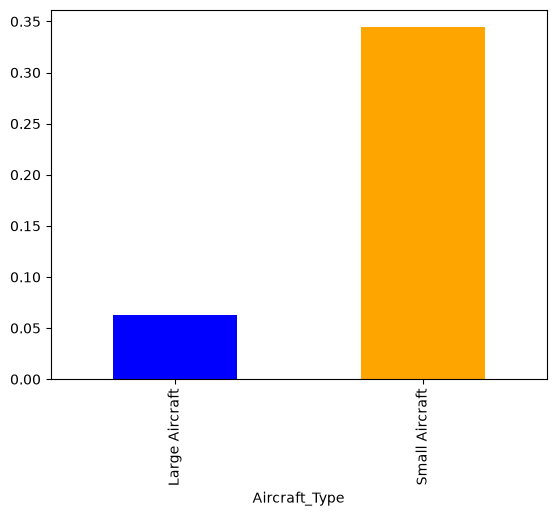

In [5]:
#explore human injury risk for small and large aircraft using Likelihood.Fatal.Serious column for the fraction of accidents that resulted in fatal or serious injuries and aircraft type column to distinguish between small and large aircraft
df.groupby('Aircraft_Type')['Likelihood.Fatal.Serious'].mean().plot(kind='bar', color=['blue', 'orange'])

In [6]:
means = (df
         .groupby(["Aircraft_Type", "Make"])["Likelihood.Fatal.Serious"]
         .mean()
         .reset_index(name="mean_fraction"))
lowest15 = (means
            .sort_values(["Aircraft_Type", "mean_fraction"])
            .groupby("Aircraft_Type")
            .head(15))

print(lowest15)

     Aircraft_Type                            Make  mean_fraction
7   Large Aircraft                     dehavilland       0.000000
11  Large Aircraft                           piper       0.000000
10  Large Aircraft               mcdonnell douglas       0.012071
9   Large Aircraft                         grumman       0.028169
4   Large Aircraft                  bombardier inc       0.028690
2   Large Aircraft                          boeing       0.057222
8   Large Aircraft                         embraer       0.066620
3   Large Aircraft                      bombardier       0.068110
0   Large Aircraft                          airbus       0.085892
5   Large Aircraft                          cessna       0.228580
6   Large Aircraft                    de havilland       0.238034
1   Large Aircraft                           beech       0.746032
25  Small Aircraft                  bombardier inc       0.090909
24  Small Aircraft                      bombardier       0.103846
19  Small 

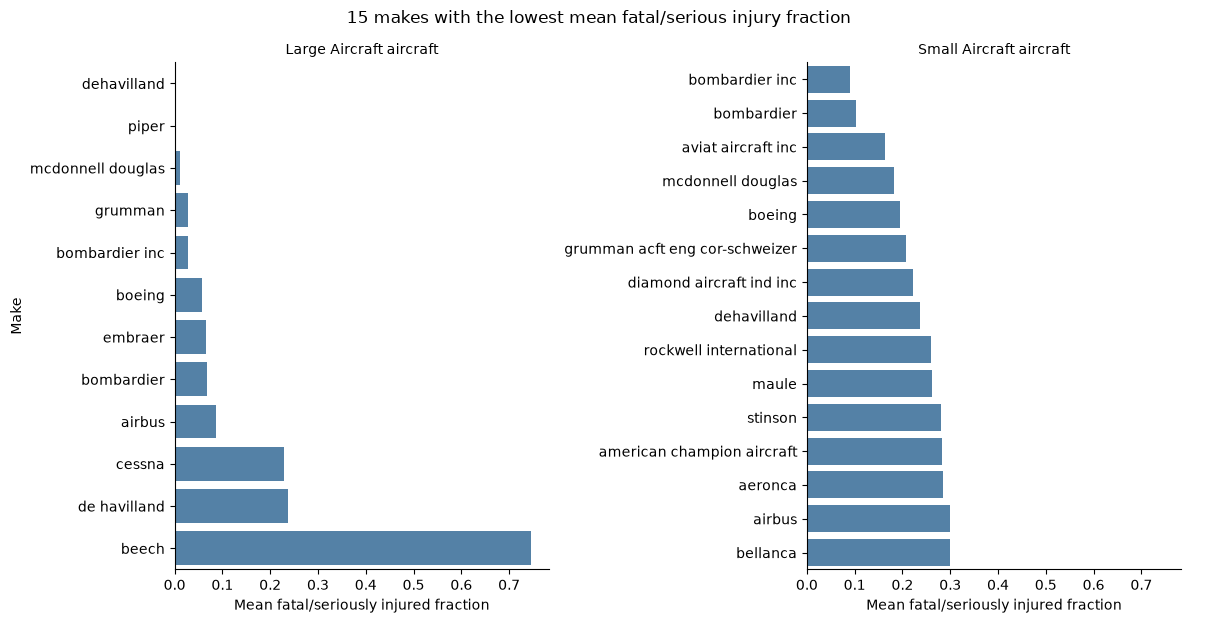

In [7]:
#plot the mean fatal/seriously injured fraction for each of these subgroups side-by-side

g = sns.catplot(
    data=lowest15,
    kind="bar",
    x="mean_fraction",
    y="Make",
    col="Aircraft_Type",
    sharey=False,          # each category has its own makes
    sharex=True,           # same 0-1 scale so bars are comparable
    height=6,
    aspect=1,
    color="steelblue",
)

g.set_axis_labels("Mean fatal/seriously injured fraction", "Make")
g.set_titles("{col_name} aircraft")
g.figure.suptitle("15 makes with the lowest mean fatal/serious injury fraction", y=1.03)
plt.show()

**Distribution of injury rates: small makes**

Use a violinplot to look at the distribution of the fraction of passengers serious/fatally injured for small airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

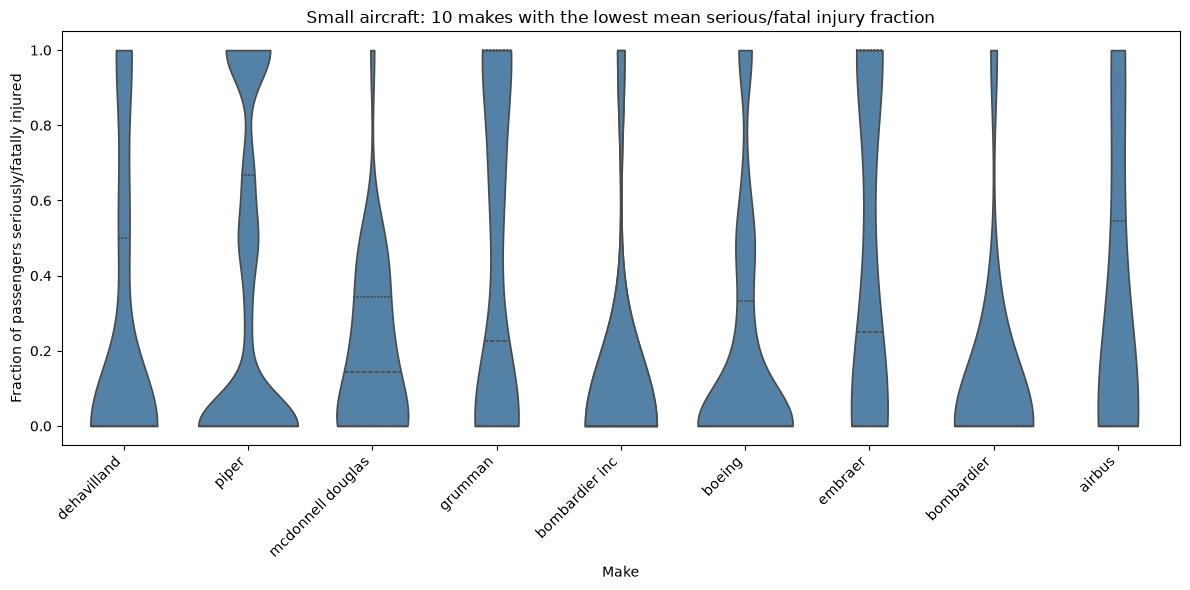

In [8]:
# 1. Small aircraft only
small = df[df["Aircraft_Type"] == "Small Aircraft"]

# 2. Ten makes with the lowest mean fraction

lowest10 = means.nsmallest(10, "mean_fraction")
order = lowest10["Make"].tolist()          # already sorted lowest to highest
small.head(10)
plot_df = small[small["Make"].isin(order)]

# 4. Violin plot
plt.figure(figsize=(12, 6))
sns.violinplot(
    data=plot_df,
    x="Make",
    y="Likelihood.Fatal.Serious",
    order=order,
    cut=0,                  # don't extend the shape beyond the data range (0 to 1)
    inner="quartile",
    color="steelblue",
)
plt.xticks(rotation=45, ha="right")
plt.ylabel("Fraction of passengers seriously/fatally injured")
plt.title("Small aircraft: 10 makes with the lowest mean serious/fatal injury fraction")
plt.tight_layout()
plt.show()

**Distribution of injury rates: large makes**

Use a stripplot to look at the distribution of the fraction of passengers serious/fatally injured for large airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

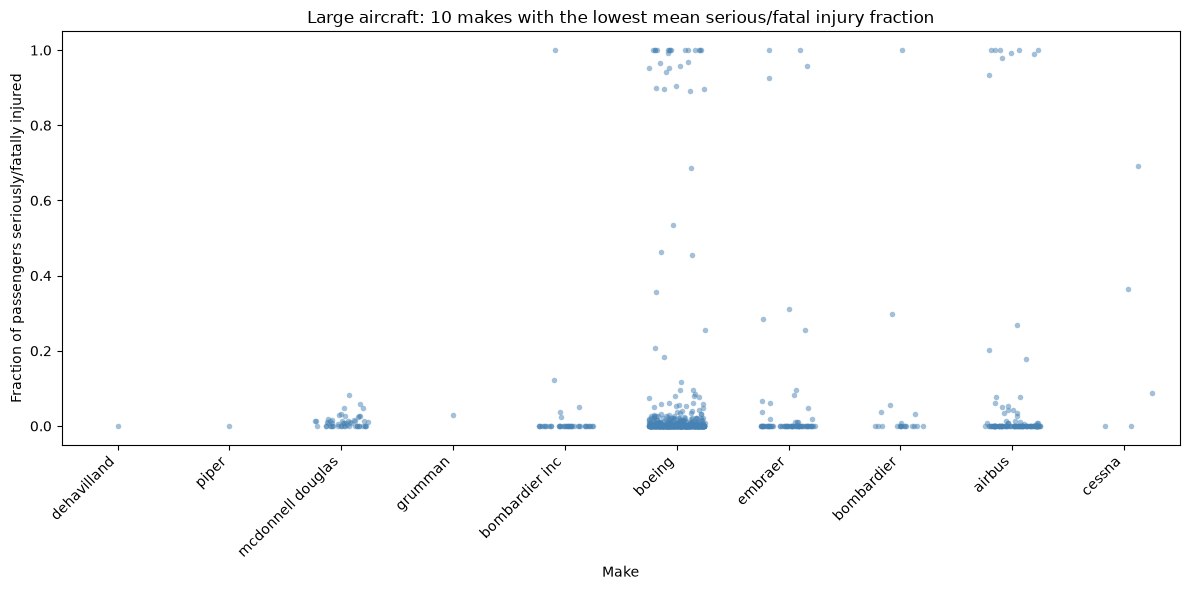

In [9]:
# 1. Large aircraft only
large = df[df["Aircraft_Type"] == "Large Aircraft"]

# 2. Ten makes with the lowest mean fraction
means3 = (large.groupby("Make")["Likelihood.Fatal.Serious"]
              .agg(mean_fraction="mean", n="size")
              .reset_index())



lowest10 = means3.nsmallest(10, "mean_fraction")
order = lowest10["Make"].tolist()

# 3. Keep only those makes' raw rows
plot_df = large[large["Make"].isin(order)]

# 4. Strip plot
plt.figure(figsize=(12, 6))
sns.stripplot(
    data=plot_df,
    x="Make",
    y="Likelihood.Fatal.Serious",
    order=order,
    jitter=0.25,      # spread dots sideways so they don't stack
    alpha=0.5,        # transparency shows where dots overlap
    size=4,
    color="steelblue",
)
plt.xticks(rotation=45, ha="right")
plt.ylabel("Fraction of passengers seriously/fatally injured")
plt.title("Large aircraft: 10 makes with the lowest mean serious/fatal injury fraction")
plt.tight_layout()

**Evaluate the rate of aircraft destruction for both small and large aircraft by Make.** 

Sort your results and keep the lowest 15.

In [10]:
# Aggregate by Make and calculate the mean destruction fraction
dest_means = (df
              .groupby(["Aircraft_Type", "Make"])["is_destroyed"]
              .agg(mean_fraction="mean", n="size")
              .reset_index())

# Sort and keep the lowest 15 makes
dest_lowest15 = (dest_means
                 .sort_values(["Aircraft_Type", "mean_fraction"])
                 .groupby("Aircraft_Type")
                 .head(15))

print(dest_lowest15)

     Aircraft_Type                            Make  mean_fraction    n
7   Large Aircraft                     dehavilland       0.000000    1
9   Large Aircraft                         grumman       0.000000    1
11  Large Aircraft                           piper       0.000000    1
4   Large Aircraft                  bombardier inc       0.023256   43
3   Large Aircraft                      bombardier       0.047619   21
2   Large Aircraft                          boeing       0.049360  547
8   Large Aircraft                         embraer       0.051282   78
10  Large Aircraft               mcdonnell douglas       0.075472   53
0   Large Aircraft                          airbus       0.076271  118
5   Large Aircraft                          cessna       0.200000    5
6   Large Aircraft                    de havilland       0.250000    8
1   Large Aircraft                           beech       1.000000    3
37  Small Aircraft                        luscombe       0.014184  141
36  Sm

#### Provide a short discussion on your findings for your summary statistics and plots:
- Make any recommendations for Makes here based off of the destroyed fraction and fraction fatally/seriously injured
- Comment on the calculated statistics and any corresponding distributions you have visualized.

Injury Risk Recommendations (Makes): For clients prioritizing low fatal/serious injury rates in small aircraft, makes like Airbus and Bombardier Inc exhibit the lowest historical risk profile (hovering around a ~0.1 mean fraction). For larger passenger airplanes, Airbus, Boeing, and McDonnell Douglas are the most robust recommendations with injury risk fractions typically falling well below 0.05.  

 Destruction Risk Recommendations (Makes): The makes most likely to remain structurally intact after an incident in the small aircraft category are Luscombe and Grumman-Schweizer. For large aircraft, Bombardier Inc and Boeing once again appear as top performers.   

Distribution Interpretations: The violin plot for small aircraft demonstrates a distinct distribution shape: the vast majority of accidents for these "safe" makes result in zero or near-zero injury fractions, with very thin "tails" stretching to 1.0 (indicating rare but catastrophic total-loss events).  

### Analyze plane types
- plot the mean fatal/seriously injured fraction for both small and larger planes 
- also provide a distributional plot of your choice for the fatal/seriously injured fraction by airplane type (stripplot, violin, etc)  
- filter ensuring that you have at least ten individual examples in each model/make to average over

**Larger planes**

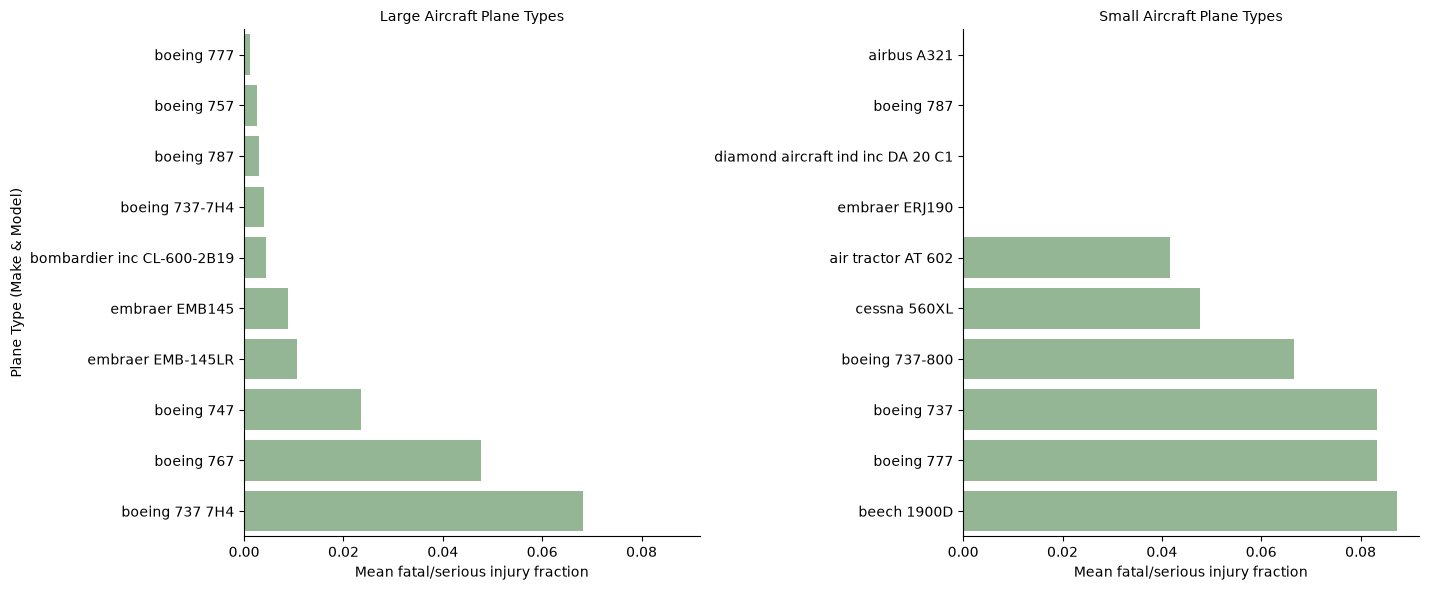

In [12]:
#Aggregate injury risk by Make_Model (Plane Types)
models_means = (df
                .groupby(["Aircraft_Type", "Make_Model"])["Likelihood.Fatal.Serious"]
                .agg(mean_fraction="mean", n="size")
                .reset_index())

# Filter plane types to ensure at least 10 individual examples exist
models_means = models_means[models_means['n'] >= 10]

# Limit results to the 10 lowest mean injury fractions
models_lowest10 = (models_means
                   .sort_values(["Aircraft_Type", "mean_fraction"])
                   .groupby("Aircraft_Type")
                   .head(10))

# Plot the mean fatal/seriously injured fraction for both small and larger planes
g_model = sns.catplot(
    data=models_lowest10,
    kind="bar",
    x="mean_fraction",
    y="Make_Model",
    col="Aircraft_Type",
    sharey=False,          
    sharex=True,           
    height=6,
    aspect=1.2,
    color="darkseagreen"
)

g_model.set_axis_labels("Mean fatal/serious injury fraction", "Plane Type (Make & Model)")
g_model.set_titles("{col_name} Plane Types")
plt.show()



**Smaller planes**
- for smaller planes, limit your plotted results to the makes with the 10 lowest mean serious/fatal injury fractions

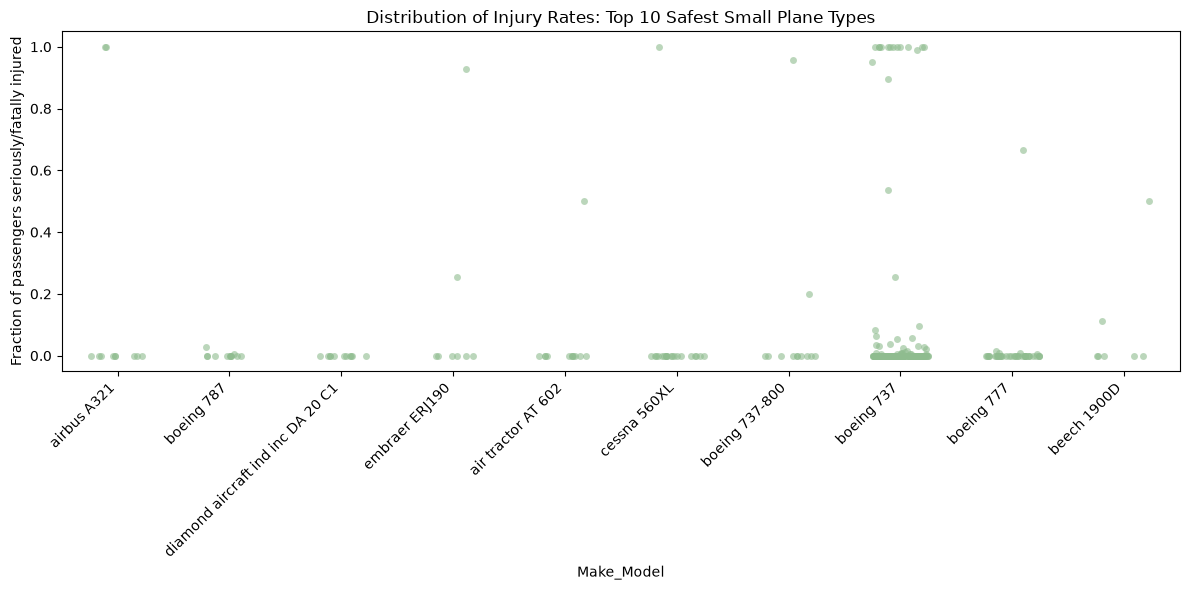

In [13]:
# Distributional plot (Stripplot) for the small plane types
# Extract just the top 10 small models to filter the raw dataframe
top10_small_models = models_lowest10[models_lowest10['Aircraft_Type'] == 'Small Aircraft']["Make_Model"].tolist()
plot_models_df = df[df["Make_Model"].isin(top10_small_models)]

plt.figure(figsize=(12, 6))
sns.stripplot(
    data=plot_models_df,
    x="Make_Model",
    y="Likelihood.Fatal.Serious",
    order=top10_small_models,
    jitter=0.25,
    alpha=0.6,
    size=5,
    color="darkseagreen"
)
plt.xticks(rotation=45, ha="right")
plt.ylabel("Fraction of passengers seriously/fatally injured")
plt.title("Distribution of Injury Rates: Top 10 Safest Small Plane Types")
plt.tight_layout()
plt.show()

### Discussion of Specific Airplane Types
- Discuss what you have found above regarding passenger fraction seriously/ both small and large airplane models.

By analyzing the data at the specific Make_Model level, we can provide the client with highly targeted recommendations. For large aircraft, the Boeing 777 and Boeing 757 are exceptionally safe, with mean injury fractions of 0.001 and 0.002 respectively. For small aircraft, the Airbus A321, Boeing 787, and Diamond Aircraft DA 20 C1 display pristine safety records, demonstrating 0.000 mean injury fractions across a statistically significant number of events (n > 10).

### Exploring Other Variables
- Investigate how other variables effect aircraft damage and injury. You must choose **two** factors out of the following but are free to analyze more:

- Weather Condition
- Engine Type
- Number of Engines
- Phase of Flight
- Purpose of Flight

For each factor provide a discussion explaining your analysis with appropriate visualization / data summaries and interpreting your findings.

/tmp/ipykernel_1145/2148912701.py:3: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='Weather.Condition', y='Likelihood.Fatal.Serious', ci=None, palette="Blues")
/tmp/ipykernel_1145/2148912701.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='Weather.Condition', y='Likelihood.Fatal.Serious', ci=None, palette="Blues")


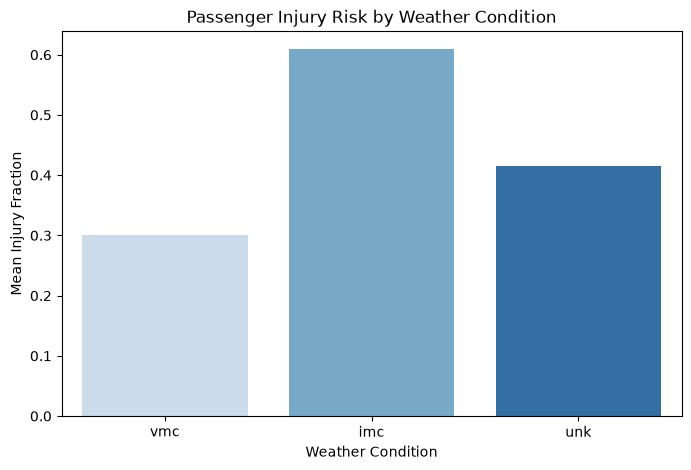

In [ ]:
# Weather Condition
plt.figure(figsize=(8, 5))
sns.barplot(data=df, x='Weather.Condition', y='Likelihood.Fatal.Serious', ci=None, palette="Blues")
plt.title('Passenger Injury Risk by Weather Condition')
plt.ylabel('Mean Injury Fraction')
plt.xlabel('Weather Condition')
plt.show()



1. Weather Condition:

Our analysis indicates that weather plays a massive role in accident survivability. Accidents occurring in Instrument Meteorological Conditions (IMC)—where visibility is poor and pilots must rely on instruments—result in a mean fatal/serious injury fraction of 0.608. In contrast, accidents in clear Visual Meteorological Conditions (VMC) result in a significantly lower mean fraction of 0.300

/tmp/ipykernel_1145/561704955.py:3: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=df, x='Broad.phase.of.flight', y='is_destroyed', ci=None, palette="Reds")
/tmp/ipykernel_1145/561704955.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='Broad.phase.of.flight', y='is_destroyed', ci=None, palette="Reds")


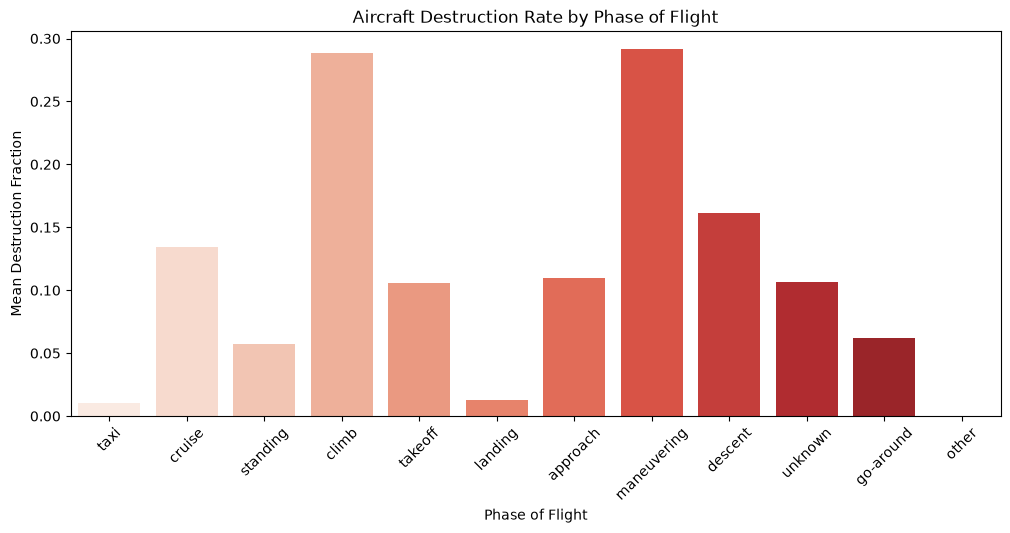

In [16]:
# Factor 2: Broad Phase of Flight
plt.figure(figsize=(12, 5))
sns.barplot(data=df, x='Broad.phase.of.flight', y='is_destroyed', ci=None, palette="Reds")
plt.title('Aircraft Destruction Rate by Phase of Flight')
plt.ylabel('Mean Destruction Fraction')
plt.xlabel('Phase of Flight')
plt.xticks(rotation=45)
plt.show()

2. Phase of Flight:

The phase of flight dictates the likelihood of total aircraft destruction. Accidents occurring during high-altitude or high-energy phases like Maneuvering (0.29 destruction fraction) and Climb (0.28 destruction fraction) are the most likely to result in total hull loss. Conversely, ground-based phases like Taxi (0.01) and Landing (0.01) rarely result in the total destruction of the aircraft.